In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/content/drive/MyDrive/rsna-pneumonia-detection-challenge/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All"
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

In [ ]:
!pip install pydicom

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import pydicom
from glob import glob
import matplotlib.patches as patches

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
labels = pd.read_csv("/content/drive/MyDrive/rsna-pneumonia-detection-challenge/stage_2_train_labels.csv")
class_info = pd.read_csv("/content/drive/MyDrive/rsna-pneumonia-detection-challenge/stage_2_detailed_class_info.csv")

df = pd.merge(labels, class_info, on="patientId", how="left")
df.sample(4)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


,patientId,x,y,width,height,Target,class
28655,cc118833-83a6-4f8f-ba7a-0e69faaaee72,564.0,288.0,306.0,548.0,1,Lung Opacity
565,074f91b5-e915-4b6f-bdf0-af1ee55ebd9b,607.0,178.0,301.0,684.0,1,Lung Opacity
24101,b36ddceb-a4c3-4f3e-9b95-cac57da3d0b9,605.0,405.0,187.0,359.0,1,Lung Opacity
25894,bb509940-e147-4ff1-806b-a82890182d5b,508.0,109.0,217.0,589.0,1,Lung Opacity


In [ ]:
print("NaN rows:", df['class'].isna().sum())


NaN rows: 0


Total Images: 26684
Total Rows: 37629


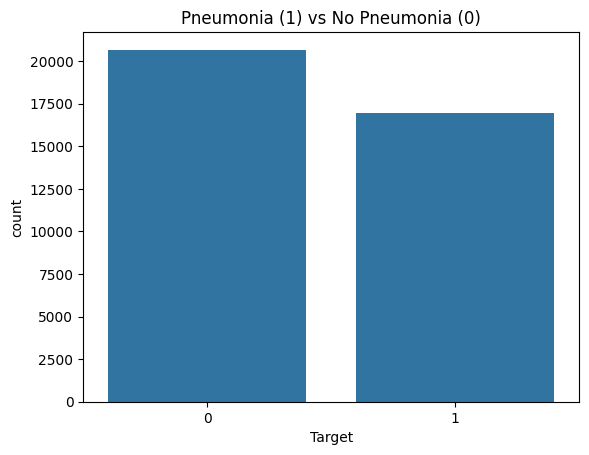

Patients with Pneumonia: 6012
Patients without Pneumonia: 20672


In [ ]:
print("Total Images:", df['patientId'].nunique())
print("Total Rows:", df.shape[0])
# Plot target distribution
sns.countplot(data=df, x='Target')
plt.title('Pneumonia (1) vs No Pneumonia (0)')
plt.show()
# Unique patientId per class
print("Patients with Pneumonia:", df[df['Target']==1]['patientId'].nunique())
print("Patients without Pneumonia:", df[df['Target']==0]['patientId'].nunique())

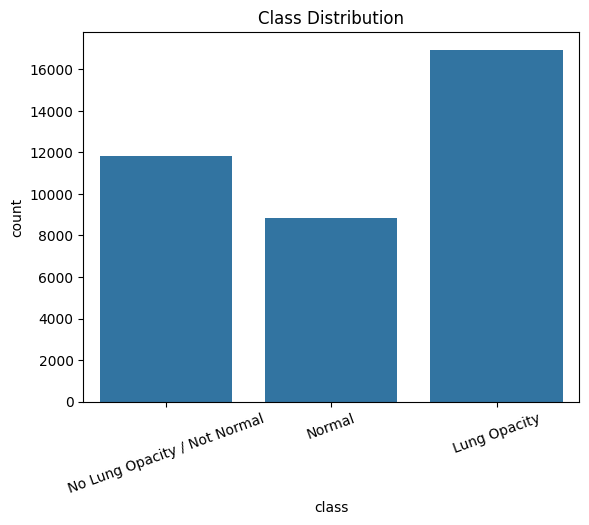

In [ ]:
sns.countplot(data=df, x='class')
plt.title('Class Distribution')
plt.xticks(rotation=20)
plt.show()

In [ ]:
def show_dicom_image(patient_id, bbox=False):
   dicom_path = f"/content/drive/MyDrive/rsna-pneumonia-detection-challenge/stage_2_train_images/{patient_id}.dcm"
   ds = pydicom.dcmread(dicom_path)
   fig, ax = plt.subplots(1, 1, figsize=(8, 8))
   ax.imshow(ds.pixel_array, cmap='gray')
   if bbox:
       records = df[df['patientId'] == patient_id]
       for _, row in records.iterrows():
           if row['Target'] == 1:
               rect = patches.Rectangle(
                   (row['x'], row['y']), row['width'], row['height'],
                   linewidth=2, edgecolor='red', facecolor='none'
               )
               ax.add_patch(rect)
   plt.title(patient_id)
   plt.show()

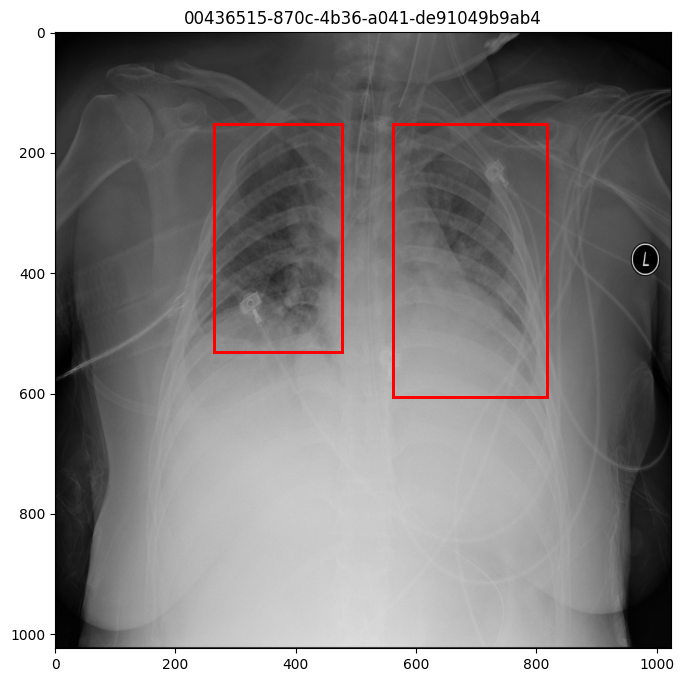

In [ ]:
pneumonia_patients = df[df['Target']==1]['patientId'].unique()
show_dicom_image(pneumonia_patients[0], bbox=True)

In [ ]:
!pip install -q pydicom opencv-python

In [ ]:
import os, cv2, pydicom
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.model_selection import train_test_split
from tensorflow.keras import layers, Model

In [ ]:
IMG_DIR = '/content/drive/MyDrive/rsna-pneumonia-detection-challenge/stage_2_train_images'
LABEL_PATH = '/content/drive/MyDrive/rsna-pneumonia-detection-challenge/stage_2_train_labels.csv'
IMG_SIZE = 128
BATCH_SIZE = 8
EPOCHS = 5
# ---------------------------
# LOAD LABELS
# ---------------------------
labels = pd.read_csv(LABEL_PATH)

# group by patientId (one row = one image)
grouped = labels.groupby("patientId").agg(list).reset_index()

# split train / validation
train_group, val_group = train_test_split(grouped, test_size=0.2, random_state=42)

print("Train size:", len(train_group))
print("Validation size:", len(val_group))

Train size: 21347
Validation size: 5337


In [ ]:
def load_image_and_label(row):
    pid = row['patientId']
    dicom_path = os.path.join(IMG_DIR, pid + ".dcm")
    ds = pydicom.dcmread(dicom_path)

    img = ds.pixel_array.astype(np.float32)
    img = cv2.resize(img, (IMG_SIZE, IMG_SIZE))
    img = np.stack([img, img, img], axis=-1) / 255.0

    # get target
    target = row['Target'][0]

    # if no pneumonia
    if target == 0:
        bbox = np.array([0,0,0,0], dtype=np.float32)
        label = np.array(0, dtype=np.int32)
    else:
        x, y, w, h = row['x'][0], row['y'][0], row['width'][0], row['height'][0]

        w_ratio = IMG_SIZE / ds.Columns
        h_ratio = IMG_SIZE / ds.Rows

        x1 = (x * w_ratio) / IMG_SIZE
        y1 = (y * h_ratio) / IMG_SIZE
        x2 = ((x + w) * w_ratio) / IMG_SIZE
        y2 = ((y + h) * h_ratio) / IMG_SIZE

        bbox = np.array([x1, y1, x2, y2], dtype=np.float32)
        label = np.array(1, dtype=np.int32)

    return img, bbox, label

In [ ]:
def make_dataset(df, shuffle=True):
    def gen():
        for _, row in df.iterrows():
            img, bbox, label = load_image_and_label(row)
            yield img, {"class": label, "bbox": bbox}

    output_signature = (
        tf.TensorSpec(shape=(IMG_SIZE, IMG_SIZE, 3), dtype=tf.float32),
        {
            "class": tf.TensorSpec(shape=(), dtype=tf.int32),
            "bbox": tf.TensorSpec(shape=(4,), dtype=tf.float32),
        }
    )

    ds = tf.data.Dataset.from_generator(gen, output_signature=output_signature)

    if shuffle:
        ds = ds.shuffle(512)

    ds = ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
    return ds

train_ds = make_dataset(train_group)
val_ds = make_dataset(val_group, shuffle=False)

In [ ]:
def build_model():
    inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))

    x = layers.Conv2D(32, 3, activation='relu', padding='same')(inputs)
    x = layers.MaxPooling2D(2)(x)

    x = layers.Conv2D(64, 3, activation='relu', padding='same')(x)
    x = layers.MaxPooling2D(2)(x)

    x = layers.Conv2D(128, 3, activation='relu', padding='same')(x)
    x = layers.GlobalAveragePooling2D()(x)

    x = layers.Dense(128, activation='relu')(x)

    cls = layers.Dense(1, activation='sigmoid', name='class')(x)
    bbox = layers.Dense(4, name='bbox')(x)

    return Model(inputs, outputs=[cls, bbox])

In [ ]:
model = build_model()

model.compile(
    optimizer='adam',
    loss={"class": "binary_crossentropy", "bbox": "mse"},
    metrics={"class": "accuracy", "bbox": "mae"}
)

model.summary()

Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_3       │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_9 (Conv2D)   │ (None, 128, 128,  │        896 │ input_layer_3[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_6     │ (None, 64, 64,    │          0 │ conv2d_9[0][0]    │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_10 (Conv2D)  │ (None, 64, 64,    │     18,496 │ max_pooling2d_6[… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_7     │ (None, 32, 32,    │          0 │ conv2d_10[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_11 (Conv2D)  │ (None, 32, 32,    │     73,856 │ max_pooling2d_7[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 128)       │          0 │ conv2d_11[0][0]   │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 128)       │     16,512 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ class (Dense)       │ (None, 1)         │        129 │ dense_3[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bbox (Dense)        │ (None, 4)         │        516 │ dense_3[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 110,405 (431.27 KB)

 Trainable params: 110,405 (431.27 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
for batch in train_ds.take(1):
    print("Labels:", batch[1].keys())
    print("Class shape:", batch[1]['class'].shape)
    print("BBox shape:", batch[1]['bbox'].shape)

Labels: dict_keys(['class', 'bbox'])
Class shape: (8,)
BBox shape: (8, 4)


In [ ]:
model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS)

Epoch 1/5
    499/Unknown 7197s 14s/step - bbox_loss: 0.0599 - bbox_mae: 0.1827 - class_accuracy: 0.7485 - class_loss: 0.5708 - loss: 0.6307

In [ ]:
model.save("rsna_simple_yolo_final.h5")

print("✅ MODEL SAVED")